In [1]:
%pip install -q pandas numpy matplotlib seaborn scikit-learn xgboost joblib

Note: you may need to restart the kernel to use updated packages.


In [1]:
import os

os.environ["LOKY_MAX_CPU_COUNT"] = "4"
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    LabelEncoder
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
df = pd.read_csv("university_student_stress_dataset.csv")

df.columns = df.columns.str.strip()

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())

Dataset shape: (3000, 18)

Column names:
['Age', 'Gender', 'Study_Hours', 'Class_Attendance', 'Tuition', 'Exam_Frequency', 'Assignment_Load', 'Sleep_Hours', 'Physical_Exercise', 'Social_Media_Use', 'Screen_Time', 'Family_Income_Level', 'Peer_Pressure', 'Family_Support', 'Anxiety_Level', 'University_Type', 'Stress_Score', 'Stress_Level']


,Age,Gender,Study_Hours,Class_Attendance,Tuition,Exam_Frequency,Assignment_Load,Sleep_Hours,Physical_Exercise,Social_Media_Use,Screen_Time,Family_Income_Level,Peer_Pressure,Family_Support,Anxiety_Level,University_Type,Stress_Score,Stress_Level
0,24,Male,9,71,No,7,4,6,Yes,6,9,Low,6,3,5,National University,20,Medium
1,24,Female,8,43,Yes,6,8,5,Yes,6,8,Medium,3,7,8,National University,22,High
2,21,Female,4,56,Yes,3,6,5,Yes,7,9,Low,2,5,3,Private University,16,Medium
3,23,Female,4,46,No,8,6,8,No,5,6,Medium,8,6,5,Private University,16,Medium
4,20,Male,8,46,No,5,1,6,Yes,0,7,Medium,5,6,2,National University,1,Low


In [3]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe(include="all").T)

print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing_Count"))

print("\nDuplicate rows:", df.duplicated().sum())

Number of rows: 3000
Number of columns: 18

Data types:
Age                    int64
Gender                   str
Study_Hours            int64
Class_Attendance       int64
Tuition                  str
Exam_Frequency         int64
Assignment_Load        int64
Sleep_Hours            int64
Physical_Exercise        str
Social_Media_Use       int64
Screen_Time            int64
Family_Income_Level      str
Peer_Pressure          int64
Family_Support         int64
Anxiety_Level          int64
University_Type          str
Stress_Score           int64
Stress_Level             str
dtype: object

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Age                  3000 non-null   int64
 1   Gender               3000 non-null   str  
 2   Study_Hours          3000 non-null   int64
 3   Class_Attendance     3000 non-null   int64
 4

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,3000.0,NaN,NaN,NaN,21.517333,1.705678,19.0,20.0,21.0,23.0,24.0
Gender,3000,2,Female,1538,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Study_Hours,3000.0,NaN,NaN,NaN,4.488667,2.858659,0.0,2.0,4.0,7.0,9.0
Class_Attendance,3000.0,NaN,NaN,NaN,68.872333,17.442576,40.0,54.0,69.0,84.0,99.0
Tuition,3000,2,No,1545,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Exam_Frequency,3000.0,NaN,NaN,NaN,5.025667,2.592023,1.0,3.0,5.0,7.0,9.0
Assignment_Load,3000.0,NaN,NaN,NaN,4.996,2.594654,1.0,3.0,5.0,7.0,9.0
Sleep_Hours,3000.0,NaN,NaN,NaN,6.519,1.687381,4.0,5.0,7.0,8.0,9.0
Physical_Exercise,3000,2,No,1551,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Social_Media_Use,3000.0,NaN,NaN,NaN,3.487,2.288721,0.0,2.0,3.0,5.0,7.0



Missing values:


,Missing_Count
Age,0
Gender,0
Study_Hours,0
Class_Attendance,0
Tuition,0
Exam_Frequency,0
Assignment_Load,0
Sleep_Hours,0
Physical_Exercise,0
Social_Media_Use,0



Duplicate rows: 0


In [4]:
TARGET = "Stress_Level"
LEAKAGE_COLUMN = "Stress_Score"

# Check required columns.
required_columns = [TARGET, LEAKAGE_COLUMN]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Required columns not found: {missing_columns}. "
        f"Actual columns: {df.columns.tolist()}"
    )

# Remove exact duplicate rows.
df = df.drop_duplicates().copy()

# A missing target cannot be used for supervised training.
df = df.dropna(subset=[TARGET]).copy()

# Remove accidental whitespace in text columns.
for col in df.select_dtypes(include=["object", "string"]).columns:
    df[col] = df[col].apply(
        lambda value: value.strip()
        if isinstance(value, str) else value
    )

print("Shape after cleaning:", df.shape)
print("Duplicate rows remaining:", df.duplicated().sum())
print("\nTarget classes:")
print(df[TARGET].value_counts(dropna=False))

Shape after cleaning: (3000, 18)
Duplicate rows remaining: 0

Target classes:
Stress_Level
Medium    1431
Low       1243
High       326
Name: count, dtype: int64


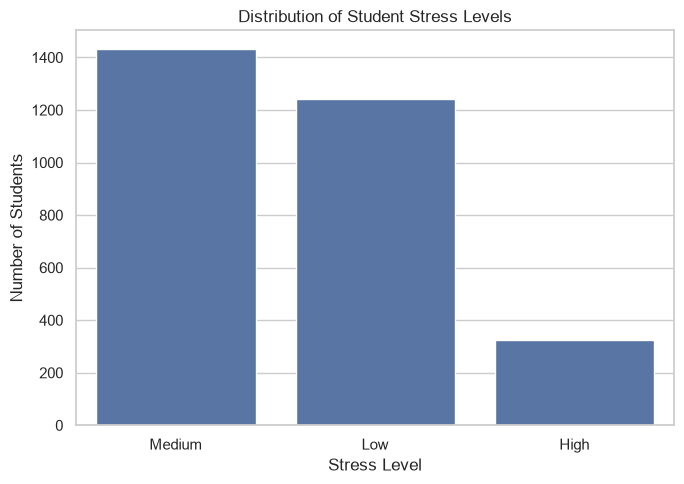

Stress_Level
Medium     47.7%
Low       41.43%
High      10.87%
Name: proportion, dtype: str


In [6]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x=TARGET,
    order=df[TARGET].value_counts().index
)

plt.title("Distribution of Student Stress Levels")
plt.xlabel("Stress Level")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

print(
    (df[TARGET].value_counts(normalize=True) * 100)
    .round(2)
    .astype(str) + "%"
)

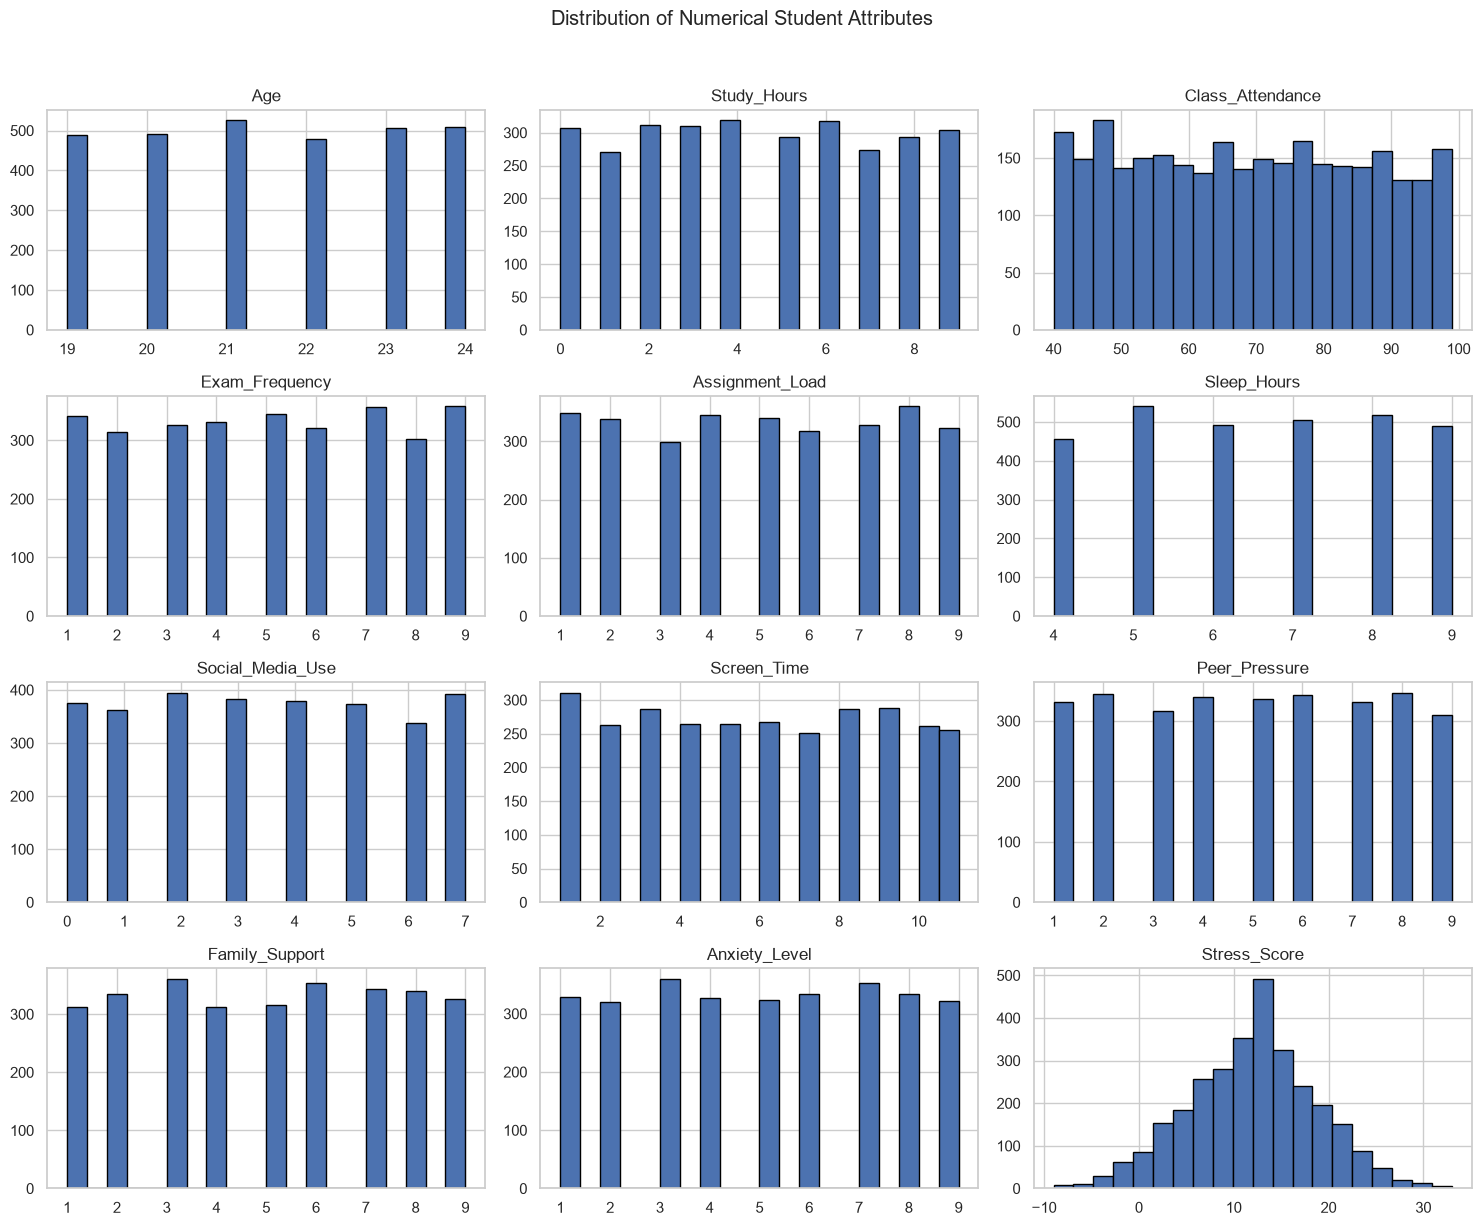

In [7]:
numeric_columns = df.select_dtypes(
    include=np.number
).columns.tolist()

df[numeric_columns].hist(
    figsize=(15, 12),
    bins=20,
    edgecolor="black"
)

plt.suptitle(
    "Distribution of Numerical Student Attributes",
    y=1.02
)
plt.tight_layout()
plt.show()

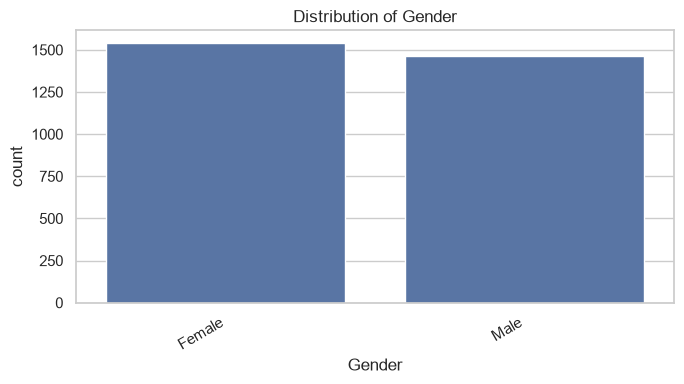

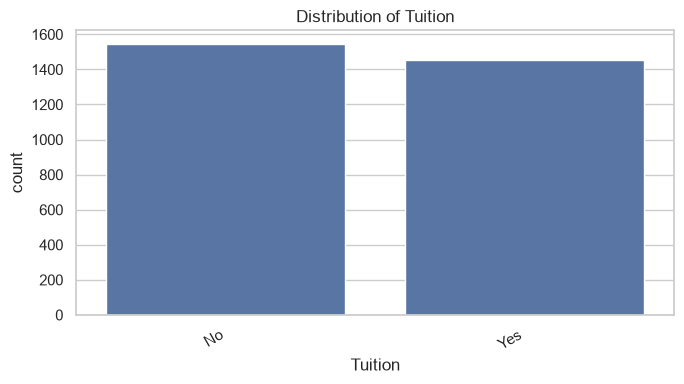

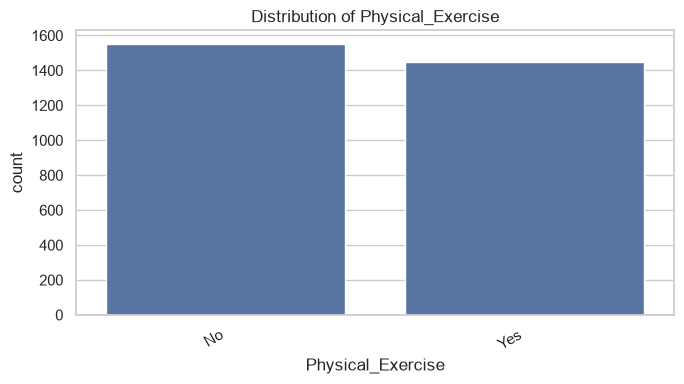

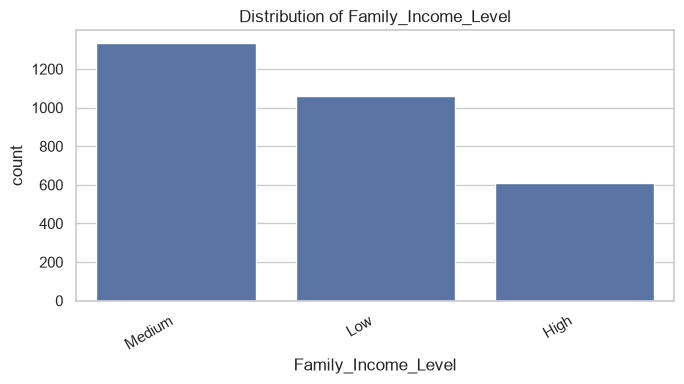

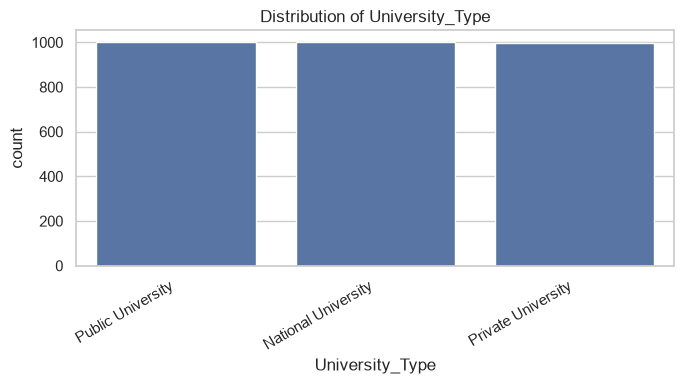

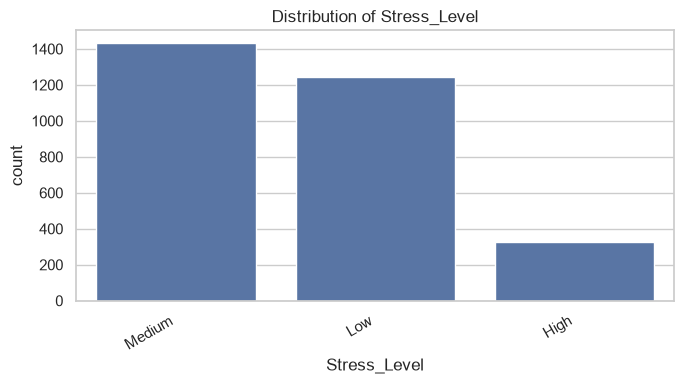

In [8]:
categorical_columns = df.select_dtypes(
    exclude=np.number
).columns.tolist()

for col in categorical_columns:
    plt.figure(figsize=(7, 4))

    sns.countplot(
        data=df,
        x=col,
        order=df[col].value_counts().index
    )

    plt.title(f"Distribution of {col}")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

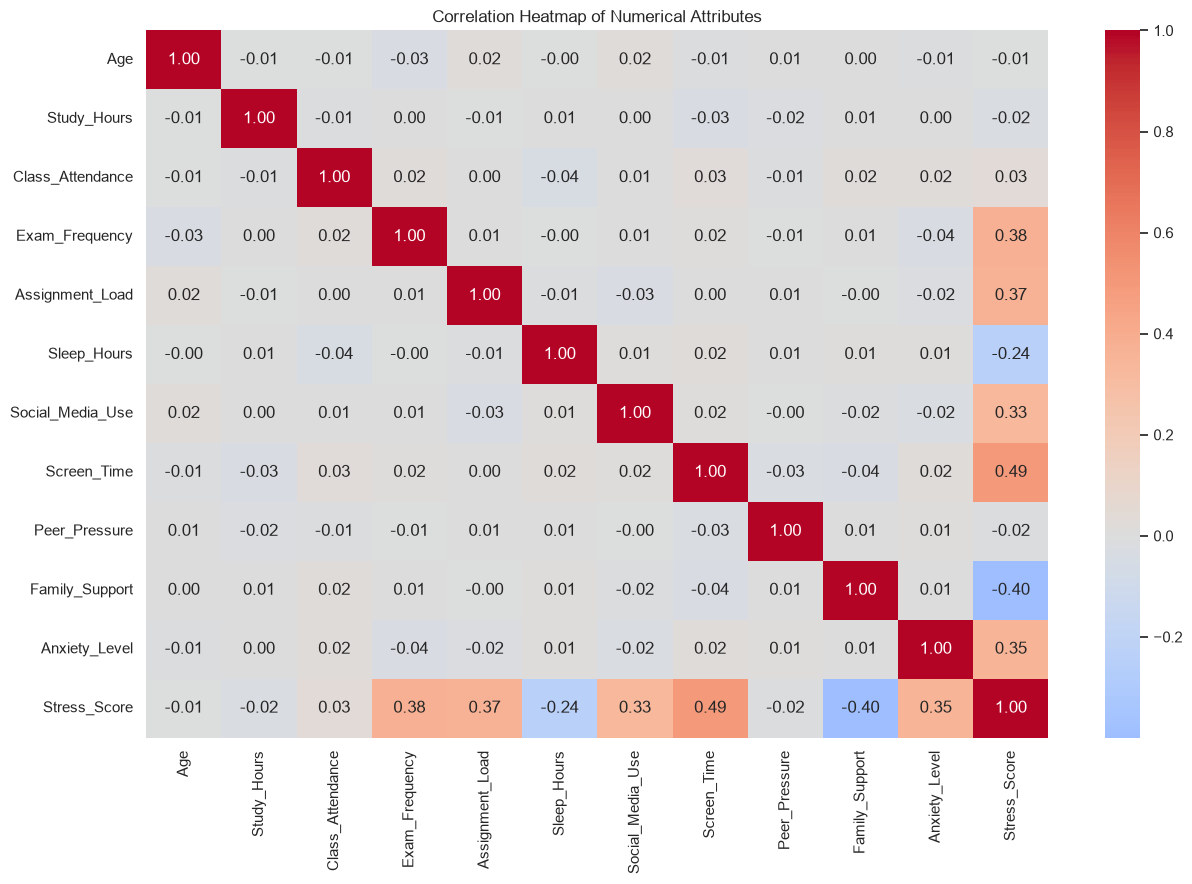

In [9]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(13, 9))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Correlation Heatmap of Numerical Attributes")
plt.tight_layout()
plt.show()

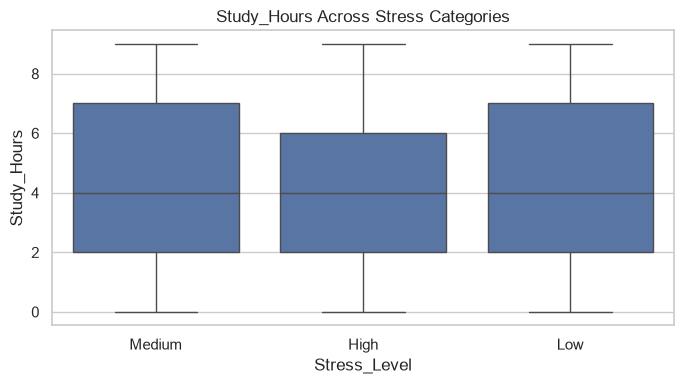

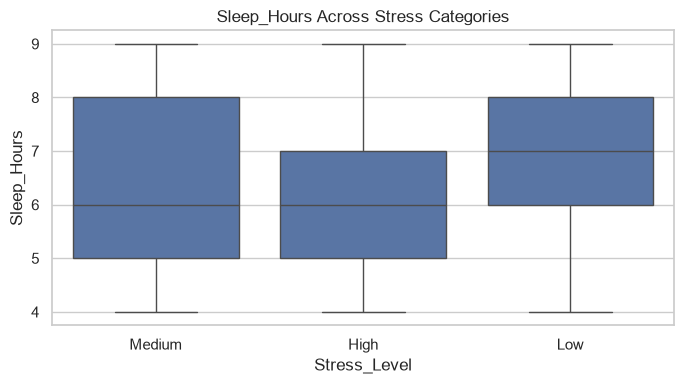

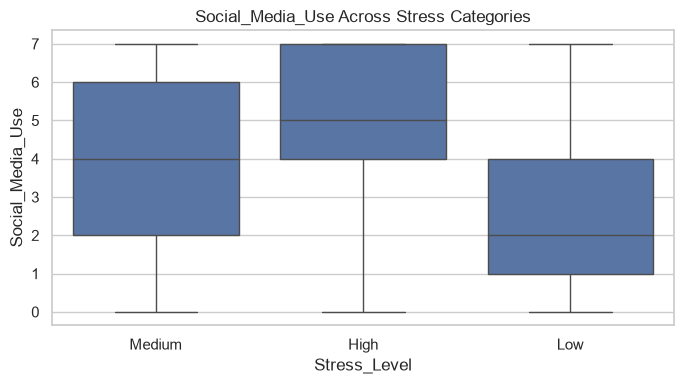

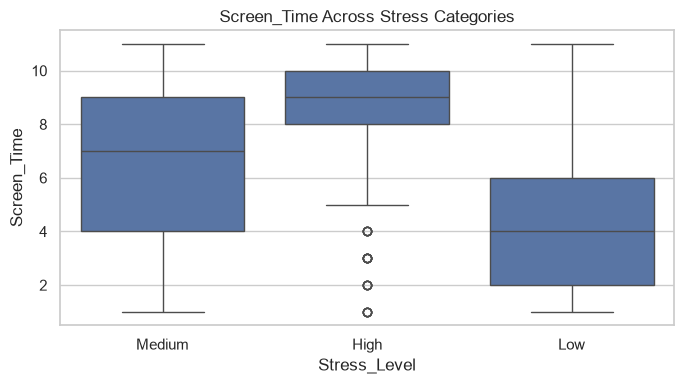

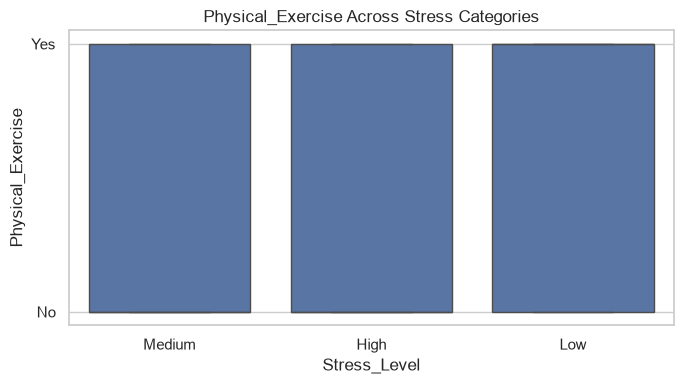

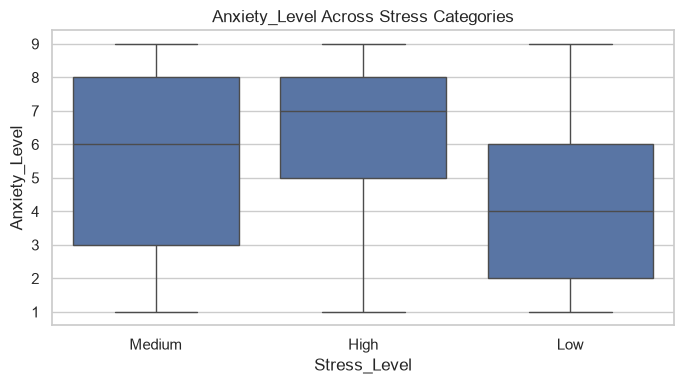

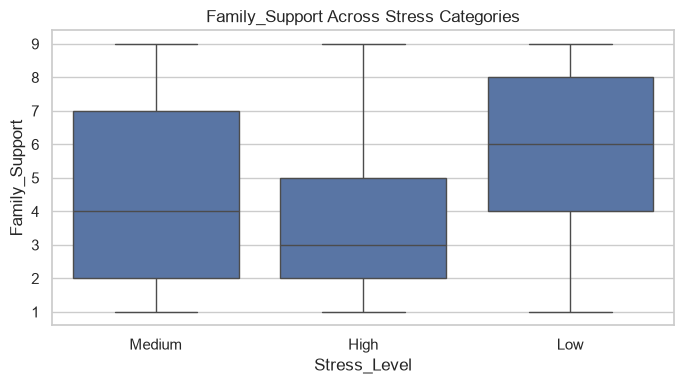

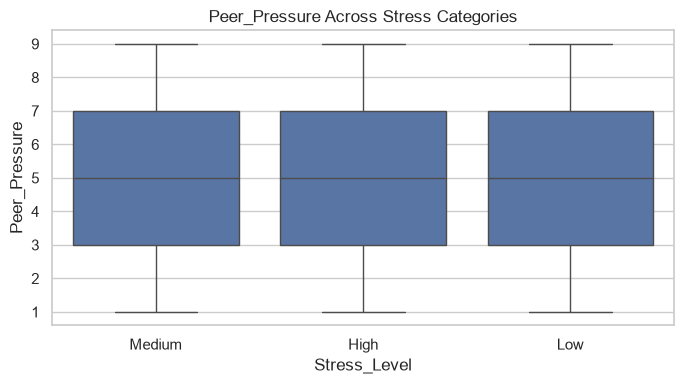

In [10]:
lifestyle_features = [
    "Study_Hours",
    "Sleep_Hours",
    "Social_Media_Use",
    "Screen_Time",
    "Physical_Exercise",
    "Anxiety_Level",
    "Family_Support",
    "Peer_Pressure"
]

for col in lifestyle_features:
    if col in df.columns:
        plt.figure(figsize=(7, 4))

        sns.boxplot(
            data=df,
            x=TARGET,
            y=col
        )

        plt.title(f"{col} Across Stress Categories")
        plt.tight_layout()
        plt.show()

In [11]:
# Exclude the target and the derived stress score.
X = df.drop(columns=[TARGET, LEAKAGE_COLUMN]).copy()
y_original = df[TARGET].astype(str)

# Encode Low / Medium / High as integers.
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_original)

print("Input feature count:", X.shape[1])
print("Input feature names:", X.columns.tolist())
print("Target categories:", list(label_encoder.classes_))

# Stratified split preserves approximate class proportions.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))

Input feature count: 16
Input feature names: ['Age', 'Gender', 'Study_Hours', 'Class_Attendance', 'Tuition', 'Exam_Frequency', 'Assignment_Load', 'Sleep_Hours', 'Physical_Exercise', 'Social_Media_Use', 'Screen_Time', 'Family_Income_Level', 'Peer_Pressure', 'Family_Support', 'Anxiety_Level', 'University_Type']
Target categories: ['High', 'Low', 'Medium']

Training records: 2400
Testing records: 600


In [12]:
numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

transformers = []

if numeric_features:
    transformers.append(
        ("numeric", numeric_pipeline, numeric_features)
    )

if categorical_features:
    transformers.append(
        ("categorical", categorical_pipeline, categorical_features)
    )

preprocessor = ColumnTransformer(
    transformers=transformers,
    remainder="drop"
)

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)
print("Preprocessing pipeline created.")

Numerical features: ['Age', 'Study_Hours', 'Class_Attendance', 'Exam_Frequency', 'Assignment_Load', 'Sleep_Hours', 'Social_Media_Use', 'Screen_Time', 'Peer_Pressure', 'Family_Support', 'Anxiety_Level']
Categorical features: ['Gender', 'Tuition', 'Physical_Exercise', 'Family_Income_Level', 'University_Type']
Preprocessing pipeline created.


In [13]:
#Phase 2

In [2]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.Defaulting to user installation because normal site-packages is not writeable

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.5/48.9 MB 1.6 MB/s eta 0:00:31
    --------------------------------------- 1.0/48.9 MB 2.2 MB/s eta 0:00:22
   - -------------------------------------- 1.6/48.9 MB 2.3 MB/s eta 0:00:21
   - -------------------------------------- 2.1/48.9 MB 2.4 MB/s eta 0:00:20
   -- ------------------------------------- 2.9/48.9 MB 2.5 MB/s eta 0:00:19
   -- ------------------------------------- 3.7/48.9 MB 2.8 MB/s eta 0:00:17
   --- ------------------------------------ 4.5/48.9 MB 2.9 MB/s eta 0:00:16
   ---- ----------------------------------- 5.2/48.9 MB 3.0 MB/s eta 0:00:15
   ---- ----------------------------------- 6.0/48.9 MB 3.0 MB/s eta 0:00:15
   ----- --------------

In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import VotingClassifier

from xgboost import XGBClassifier

from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate,
    GridSearchCV
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Model imports completed.")

Model imports completed.


In [15]:
n_classes = len(label_encoder.classes_)

xgb_params = {
    "n_estimators": 200,
    "max_depth": 4,
    "learning_rate": 0.05,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "objective": (
        "binary:logistic"
        if n_classes == 2
        else "multi:softprob"
    ),
    "eval_metric": (
        "logloss"
        if n_classes == 2
        else "mlogloss"
    ),
    "random_state": RANDOM_STATE,
    "n_jobs": -1
}

if n_classes > 2:
    xgb_params["num_class"] = n_classes

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE
    ),

    "SVM": SVC(
        kernel="rbf",
        C=1.0
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=6,
        random_state=RANDOM_STATE
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

   "Voting Classifier": VotingClassifier(
    estimators=[
        ("lr", LogisticRegression(
            max_iter=2000,
            random_state=RANDOM_STATE
        )),
        ("svm", SVC(
            kernel="rbf",
            probability=True,
            random_state=RANDOM_STATE
        )),
        ("dt", DecisionTreeClassifier(
            max_depth=6,
            random_state=RANDOM_STATE
        ))
     ],
     voting="soft"
    ),

    "XGBoost": XGBClassifier(
        **xgb_params
    )
}

print("Number of models:", len(models))

for name in models:
    print("-", name)

Number of models: 6
- Logistic Regression
- SVM
- Decision Tree
- KNN
- Voting Classifier
- XGBoost


In [16]:
results = []
fitted_models = {}
test_predictions = {}

for name, model in models.items():

    print("Training:", name)

    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    fitted_models[name] = pipeline
    test_predictions[name] = predictions

    results.append({
        "Model": name,

        "Accuracy": accuracy_score(
            y_test, predictions
        ),

        "Precision": precision_score(
            y_test, predictions,
            average="weighted",
            zero_division=0
        ),

        "Recall": recall_score(
            y_test, predictions,
            average="weighted",
            zero_division=0
        ),

        "Weighted F1": f1_score(
            y_test, predictions,
            average="weighted",
            zero_division=0
        ),

        "Macro F1": f1_score(
            y_test, predictions,
            average="macro",
            zero_division=0
        )
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    "Macro F1",
    ascending=False
).reset_index(drop=True)

display(results_df.round(4))

Training: Logistic Regression
Training: SVM
Training: Decision Tree
Training: KNN
Training: Voting Classifier
Training: XGBoost


,Model,Accuracy,Precision,Recall,Weighted F1,Macro F1
0,Logistic Regression,0.9967,0.9967,0.9967,0.9966,0.9936
1,Voting Classifier,0.9617,0.9637,0.9617,0.9613,0.9481
2,SVM,0.9433,0.9464,0.9433,0.9427,0.9252
3,XGBoost,0.8817,0.8915,0.8817,0.8764,0.8243
4,KNN,0.7717,0.7684,0.7717,0.7674,0.7094
5,Decision Tree,0.7167,0.7226,0.7167,0.7148,0.6832


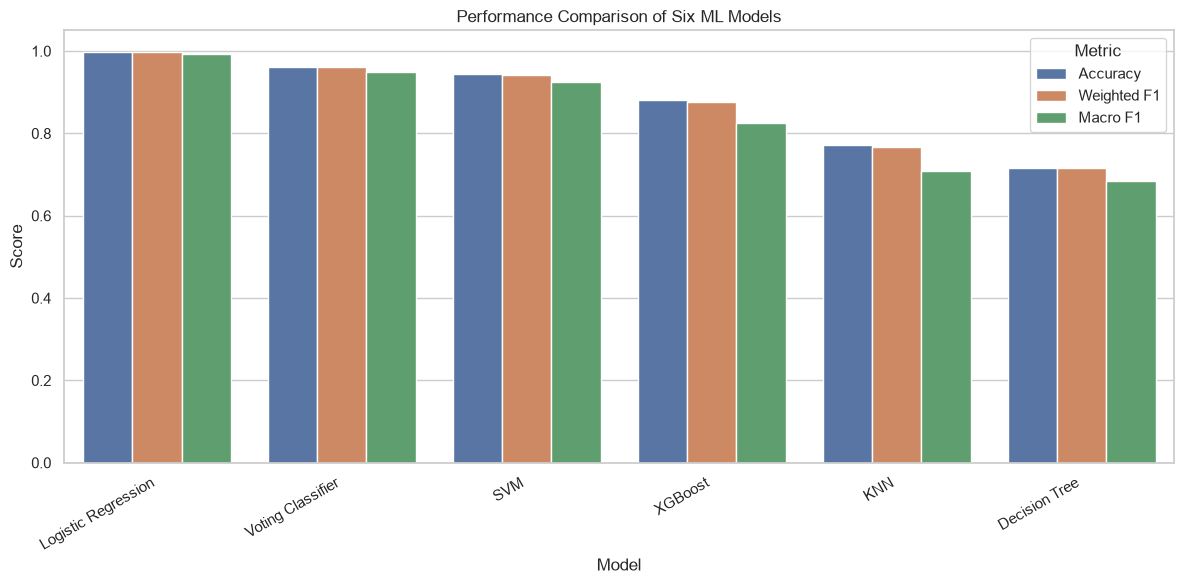

In [17]:
plot_data = results_df.melt(
    id_vars="Model",
    value_vars=["Accuracy", "Weighted F1", "Macro F1"],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=plot_data,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Performance Comparison of Six ML Models")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1.05)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

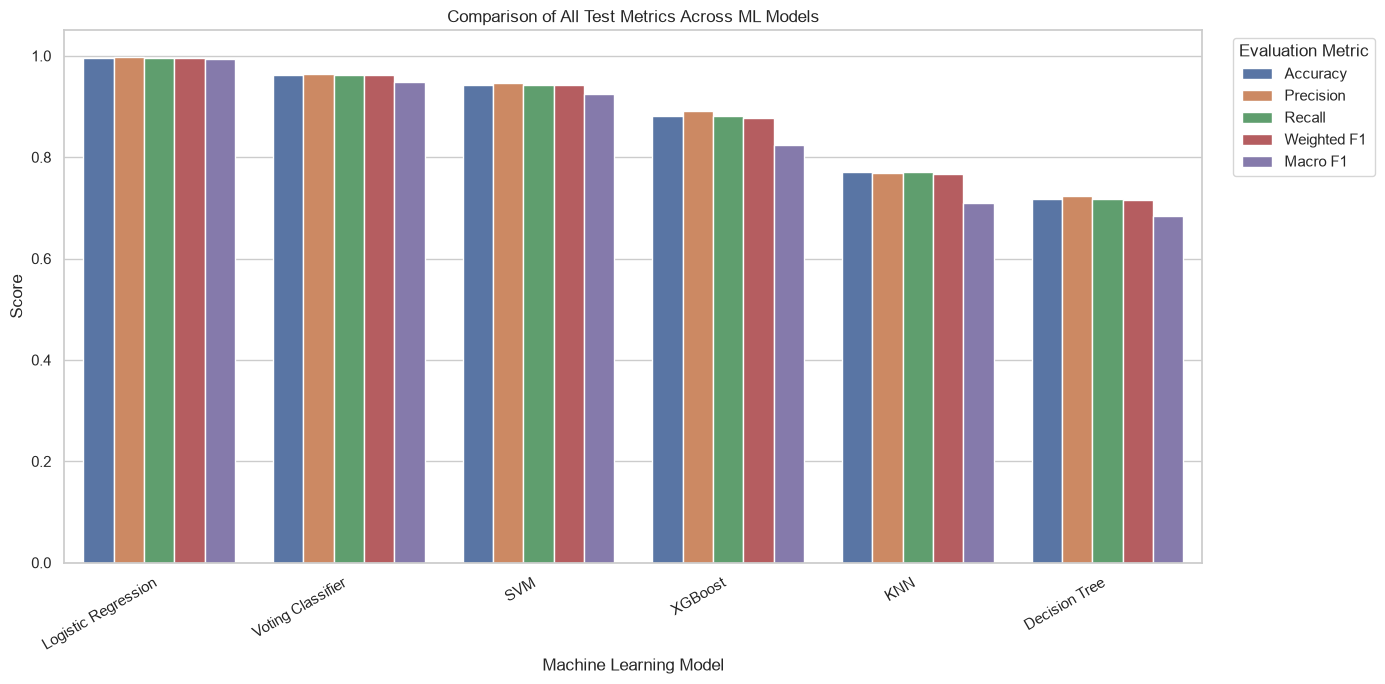

In [30]:

# Graph 5: Comparison of all test metrics

all_metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "Weighted F1",
    "Macro F1"
]

comparison_data = results_df.melt(
    id_vars="Model",
    value_vars=all_metrics,
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(14, 7))

sns.barplot(
    data=comparison_data,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Comparison of All Test Metrics Across ML Models")
plt.xlabel("Machine Learning Model")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=30, ha="right")
plt.legend(title="Evaluation Metric", bbox_to_anchor=(1.02, 1),
           loc="upper left")
plt.tight_layout()
plt.show()


In [18]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

cv_results = []

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("classifier", model)
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "f1_macro": "f1_macro",
            "f1_weighted": "f1_weighted"
        },
        n_jobs=1
    )

    cv_results.append({
        "Model": name,
        "Mean CV Accuracy": scores["test_accuracy"].mean(),
        "CV Accuracy Std": scores["test_accuracy"].std(),
        "Mean CV Macro F1": scores["test_f1_macro"].mean(),
        "CV Macro F1 Std": scores["test_f1_macro"].std(),
        "Mean CV Weighted F1": scores["test_f1_weighted"].mean()
    })

cv_results_df = pd.DataFrame(cv_results)

cv_results_df = cv_results_df.sort_values(
    "Mean CV Macro F1",
    ascending=False
).reset_index(drop=True)

display(cv_results_df.round(4))

,Model,Mean CV Accuracy,CV Accuracy Std,Mean CV Macro F1,CV Macro F1 Std,Mean CV Weighted F1
0,Logistic Regression,0.9958,0.0035,0.9925,0.0061,0.9958
1,Voting Classifier,0.9521,0.0044,0.9404,0.0077,0.9518
2,SVM,0.9237,0.0076,0.9010,0.0094,0.9230
3,XGBoost,0.8829,0.0135,0.8382,0.0186,0.8795
4,KNN,0.7467,0.0133,0.6914,0.0053,0.7422
5,Decision Tree,0.7121,0.0148,0.6671,0.0110,0.7104


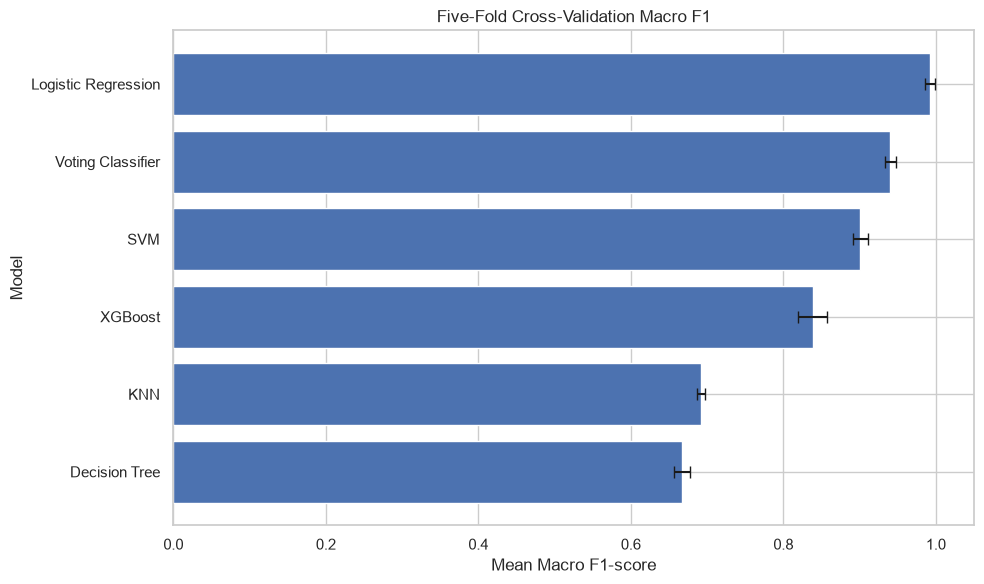

,Model,Mean CV Macro F1,CV Macro F1 Std
0,Logistic Regression,0.9925,0.0061
1,Voting Classifier,0.9404,0.0077
2,SVM,0.9010,0.0094
3,XGBoost,0.8382,0.0186
4,KNN,0.6914,0.0053
5,Decision Tree,0.6671,0.0110


In [31]:

# Graph 6: Cross-validation Macro F1 with standard-deviation error bars

cv_plot_data = cv_results_df.sort_values(
    "Mean CV Macro F1",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    cv_plot_data["Model"],
    cv_plot_data["Mean CV Macro F1"],
    xerr=cv_plot_data["CV Macro F1 Std"],
    capsize=4
)

plt.title("Five-Fold Cross-Validation Macro F1")
plt.xlabel("Mean Macro F1-score")
plt.ylabel("Model")
plt.xlim(0, 1.05)
plt.tight_layout()
plt.show()

display(
    cv_results_df[
        ["Model", "Mean CV Macro F1", "CV Macro F1 Std"]
    ].round(4)
)


Leading model by CV Macro F1: Logistic Regression


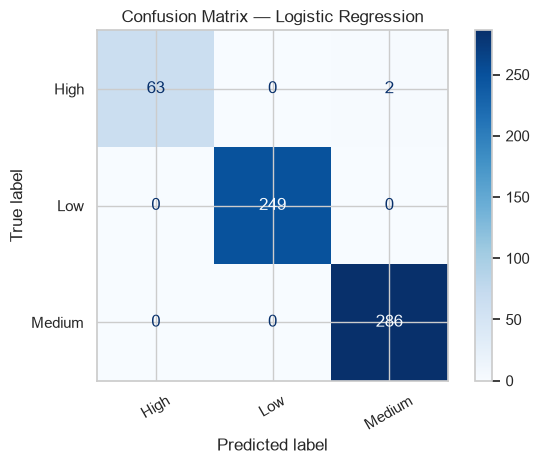

In [19]:
best_cv_name = cv_results_df.iloc[0]["Model"]
best_model = fitted_models[best_cv_name]
best_predictions = test_predictions[best_cv_name]

print("Leading model by CV Macro F1:", best_cv_name)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_predictions,
    labels=np.arange(n_classes),
    display_labels=label_encoder.classes_,
    cmap="Blues",
    values_format="d",
    xticks_rotation=30
)

plt.title(f"Best Original Model - Confusion Matrix {best_cv_name}")
plt.tight_layout()
plt.show()

In [21]:
xgb_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", XGBClassifier(**xgb_params))
])

param_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [3, 5],
    "classifier__learning_rate": [0.03, 0.1]
}

grid_search = GridSearchCV(
    estimator=xgb_pipeline,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=1,
    refit=True,
    verbose=1
)

grid_search.fit(X_train, y_train)

best_xgb = grid_search.best_estimator_

print("Best XGBoost parameters:")
print(grid_search.best_params_)

print(
    "Best cross-validation Macro F1:",
    round(grid_search.best_score_, 4)
)

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best XGBoost parameters:
{'classifier__learning_rate': 0.1, 'classifier__max_depth': 3, 'classifier__n_estimators': 200}
Best cross-validation Macro F1: 0.862


In [22]:
xgb_predictions = best_xgb.predict(X_test)

xgb_test_results = {
    "Accuracy": accuracy_score(y_test, xgb_predictions),
    "Precision": precision_score(
        y_test, xgb_predictions,
        average="weighted",
        zero_division=0
    ),
    "Recall": recall_score(
        y_test, xgb_predictions,
        average="weighted",
        zero_division=0
    ),
    "Weighted F1": f1_score(
        y_test, xgb_predictions,
        average="weighted",
        zero_division=0
    ),
    "Macro F1": f1_score(
        y_test, xgb_predictions,
        average="macro",
        zero_division=0
    )
}

display(pd.DataFrame(
    [xgb_test_results],
    index=["Tuned XGBoost"]
).round(4))

print(classification_report(
    y_test,
    xgb_predictions,
    labels=np.arange(n_classes),
    target_names=label_encoder.classes_,
    zero_division=0
))

,Accuracy,Precision,Recall,Weighted F1,Macro F1
Tuned XGBoost,0.8883,0.8948,0.8883,0.8854,0.842


              precision    recall  f1-score   support

        High       0.90      0.58      0.71        65
         Low       0.96      0.89      0.93       249
      Medium       0.83      0.95      0.89       286

    accuracy                           0.89       600
   macro avg       0.90      0.81      0.84       600
weighted avg       0.89      0.89      0.89       600



In [34]:
tuned_row = {
    "Model": "XGBoost (Tuned)",
    **xgb_test_results
}

final_results_df = pd.concat(
    [
        results_df,
        pd.DataFrame([tuned_row])
    ],
    ignore_index=True
)

display(final_results_df.round(4))

,Model,Accuracy,Precision,Recall,Weighted F1,Macro F1
0,Logistic Regression,0.9967,0.9967,0.9967,0.9966,0.9936
1,Voting Classifier,0.9617,0.9637,0.9617,0.9613,0.9481
2,SVM,0.9433,0.9464,0.9433,0.9427,0.9252
3,XGBoost,0.8817,0.8915,0.8817,0.8764,0.8243
4,KNN,0.7717,0.7684,0.7717,0.7674,0.7094
5,Decision Tree,0.7167,0.7226,0.7167,0.7148,0.6832
6,XGBoost (Tuned),0.8883,0.8948,0.8883,0.8854,0.8420


In [35]:
# Select the final model using cross-validation scores

final_cv_results = cv_results_df[
    ["Model", "Mean CV Macro F1"]
].copy()

# Add tuned XGBoost CV score
tuned_row = pd.DataFrame([{
    "Model": "XGBoost (Tuned)",
    "Mean CV Macro F1": grid_search.best_score_
}])

final_cv_results = pd.concat(
    [final_cv_results, tuned_row],
    ignore_index=True
)

# Select the highest CV Macro F1
final_cv_results = final_cv_results.sort_values(
    "Mean CV Macro F1",
    ascending=False
).reset_index(drop=True)

display(final_cv_results.round(4))

best_model_name = final_cv_results.iloc[0]["Model"]

if best_model_name == "XGBoost (Tuned)":
    best_model = best_xgb
else:
    best_model = fitted_models[best_model_name]

print("Selected using cross-validation:", best_model_name)

,Model,Mean CV Macro F1
0,Logistic Regression,0.9925
1,Voting Classifier,0.9404
2,SVM,0.9010
3,XGBoost (Tuned),0.8620
4,XGBoost,0.8382
5,KNN,0.6914
6,Decision Tree,0.6671


Selected using cross-validation: Logistic Regression


In [41]:
# Final evaluation on the untouched test set

best_predictions = best_model.predict(X_test)

final_test_results = {
    "Model": best_model_name,

    "Accuracy": accuracy_score(
        y_test, best_predictions
    ),

    "Precision": precision_score(
        y_test, best_predictions,
        average="weighted",
        zero_division=0
    ),

    "Recall": recall_score(
        y_test, best_predictions,
        average="weighted",
        zero_division=0
    ),

    "Weighted F1": f1_score(
        y_test, best_predictions,
        average="weighted",
        zero_division=0
    ),

    "Macro F1": f1_score(
        y_test, best_predictions,
        average="macro",
        zero_division=0
    )
}

final_test_df = pd.DataFrame([final_test_results])

print("Final Selected Model — Held-Out Test Results:")
display(final_test_df.round(4))



Final Selected Model — Held-Out Test Results:


,Model,Accuracy,Precision,Recall,Weighted F1,Macro F1
0,Logistic Regression,0.9967,0.9967,0.9967,0.9966,0.9936



Classification Report:
              precision    recall  f1-score   support

        High       1.00      0.97      0.98        65
         Low       1.00      1.00      1.00       249
      Medium       0.99      1.00      1.00       286

    accuracy                           1.00       600
   macro avg       1.00      0.99      0.99       600
weighted avg       1.00      1.00      1.00       600



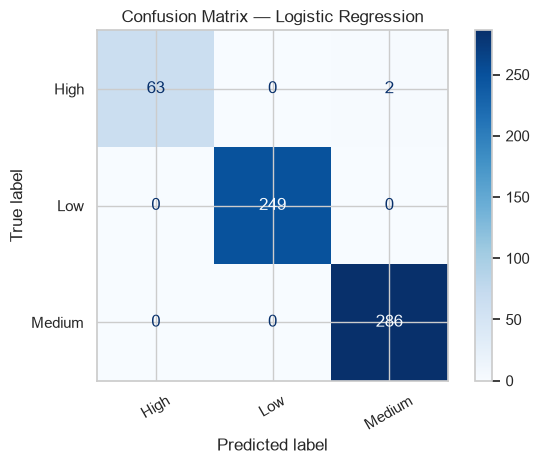

In [42]:
# Confusion Matrix for the selected model
ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_predictions,
    labels=np.arange(n_classes),
    display_labels=label_encoder.classes_,
    cmap="Blues",
    values_format="d",
    xticks_rotation=30
)

plt.title(f"Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.show()

In [40]:

from sklearn.metrics import classification_report

print(f"Classification Report - {best_model_name}\n")

print(
    classification_report(
        y_test,
        best_predictions,
        labels=np.arange(n_classes),
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

Classification Report - Logistic Regression

              precision    recall  f1-score   support

        High       1.00      0.97      0.98        65
         Low       1.00      1.00      1.00       249
      Medium       0.99      1.00      1.00       286

    accuracy                           1.00       600
   macro avg       1.00      0.99      0.99       600
weighted avg       1.00      1.00      1.00       600



In [37]:
# Save the final selected model for Streamlit deployment

import joblib

joblib.dump(
    best_model,
    "university_student_stress_model.pkl"
)

joblib.dump(
    label_encoder,
    "stress_label_encoder.pkl"
)

print("Final selected model:", best_model_name)
print("Final CV Macro F1:",
      round(final_cv_results.iloc[0]["Mean CV Macro F1"], 4))
print("Model saved successfully for deployment.")

Final selected model: Logistic Regression
Final CV Macro F1: 0.9925
Model saved successfully for deployment.



Conclusion

This project explores the prediction of university student stress levels using lifestyle, academic, and personal-support attributes.

Exploratory Data Analysis is used to study the distribution of stress categories and relationships between the available features. A preprocessing pipeline handles numerical and categorical variables before model training.

Multiple machine learning models are compared using test-set metrics and stratified cross-validation. Confusion matrices and per-class evaluation metrics are also examined to understand model errors and differences in performance between stress categories.

The final model should be selected using cross-validation results and evaluated on the held-out test set. Its performance should be interpreted carefully, especially if the dataset's stress labels were generated from rules or scores derived from the input features.

Limitations

- The results depend on the quality and representativeness of the dataset.
- Relationships found in exploratory plots do not establish causation.
- High evaluation scores do not necessarily guarantee generalization to students from other universities.
- The model predicts dataset-defined stress categories and should not be treated as a clinical assessment of a student's mental health.
